## Visulations of Results

This notebook sets out to bring the work to life - displaying some images differing in princiapal components and analysing what happens to explained variance ratios and predictions as we increase the number of principal components.

In [1]:
from src.pca import Eigendigits
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split

data = pd.read_csv('data/mnist.csv')
Y = np.array(data["digit"]) # selecting the column called digit
X = np.array(data.drop("digit", axis=1).copy())

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### Quick demo of how to use the Eigendigits class

In [2]:
# creating an Eigendigits object 
obj = Eigendigits(20)
obj.fit(X_train)
print(obj)

Eigendigits object
Number of principal components: 20
Explained variance ratio: 0.6525931091740685


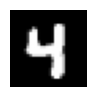

In [3]:
# picking a random image from the dataset and displaying it  
z_0 = X[58]

z_0_reshaped = z_0.reshape(28,28)
plt.figure(figsize=(1,1))
plt.imshow(z_0_reshaped, cmap='gray')
plt.axis('off')
plt.show()

In [4]:
#should equal 4 as is displayed above - here z_0 is from the training data so will be exact. This is not the case later on. 
obj.classify(X, Y, z_0)

np.int64(4)

The same image again using the principal components. 

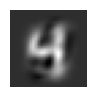

In [5]:
# projection 
z_0_projected = obj.project(X)[58]

z_0_projected = z_0_projected.reshape(28,28)
plt.figure(figsize=(1,1))
plt.imshow(z_0_projected, cmap='gray')
plt.axis('off')
plt.show()

In [6]:
def accuracy(X_test):
    """
    func for calculating the accuracy of the test set 
    """

    predictions = []
    correct_count = 0
    for idx, row in enumerate(X_test):
        x_test = row
        prediction =  obj.classify(X_train, y_train, x_test)
        predictions.append(prediction)
        if prediction == y_test[idx]:
            correct_count += 1

    return correct_count/X_test.shape[0]

Iterating over the test set, plotting the explained variance ratio and accuracy for differing numbers of principal components.

In [7]:
evr_list = []
accuracy_list = []
x_axes = np.geomspace(1, X_train.shape[1], 11)

for n_pcs in x_axes:
    n_pcs = int(n_pcs)

    obj = Eigendigits(n_pcs)
    obj.fit(X_train)
    evr_list.append(obj.explained_variance_ratio)
    accuracy_list.append(accuracy(X_test))


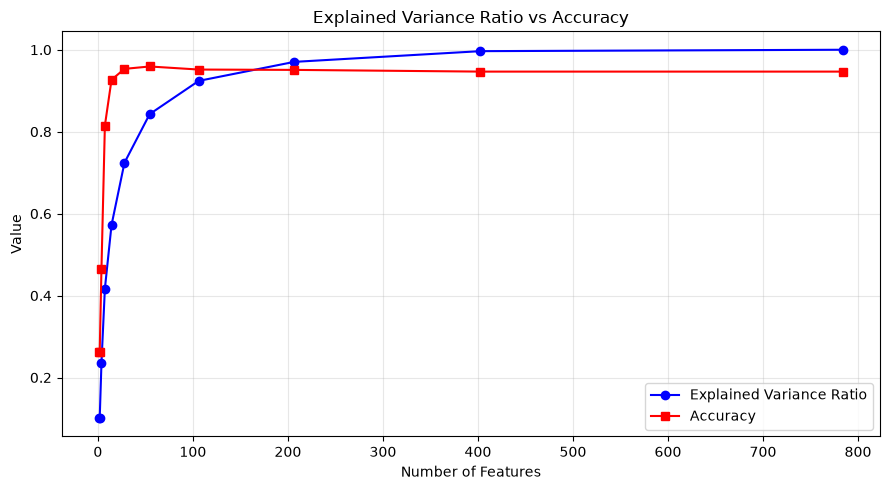

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

# Explained variance ratio
ax.plot(x_axes, evr_list, 'b-o', label='Explained Variance Ratio')

# Accuracy
ax.plot(x_axes, accuracy_list, 'r-s', label='Accuracy')

ax.set_xlabel('Number of Features')
ax.set_ylabel('Value')

ax.set_title('Explained Variance Ratio vs Accuracy')

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

Accuracy climbes very quickly then drifts slightly back down indicating that a bit of overfitting occurs. This demonstrates that retaining variance and classification are different goals. Adding more principal components, more inforamtion, after a point could be adding extra detail such as hand writing style, positioning and pixel noise that makes the classification less reliable. 

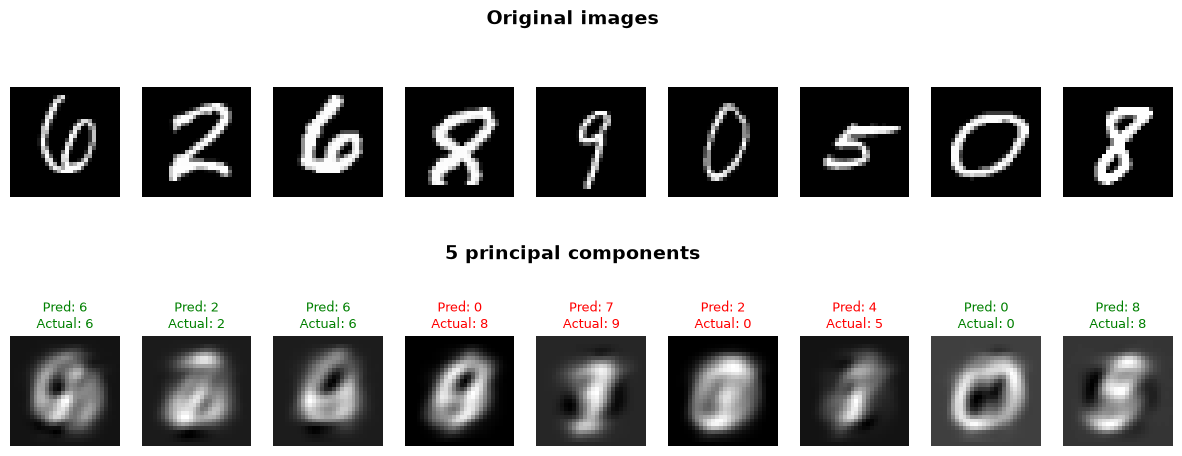

In [11]:
obj = Eigendigits(5)
obj.fit(X_train)

X_test_projected = obj.project(X_test[:9])

y_pred = []

for i, row in enumerate(X_test):
    prediction = obj.classify(X_train, y_train, row)
    y_pred.append(prediction)

train_samples = X_test[:9]
test_samples = X_test_projected[:9]

fig, axes = plt.subplots(2, 9, figsize=(15, 5))

# First row: Original images
for i in range(9):
    axes[0, i].imshow(train_samples[i].reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')

# Second row: Images reconstructed using 10 principal components
for i in range(9):
    axes[1, i].imshow(test_samples[i].reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')

    # Display predicted and actual labels
    axes[1, i].set_title(
        f'Pred: {y_pred[i]}\nActual: {y_test[i]}',
        fontsize=9,
        color='green' if y_pred[i] == y_test[i] else 'red'
    )

# Horizontal row headers
fig.text(0.5, 0.95, 'Original images',
         ha='center', fontsize=14, fontweight='bold')

fig.text(0.5, 0.48, '5 principal components',
         ha='center', fontsize=14, fontweight='bold')

plt.subplots_adjust(top=0.88, bottom=0.05, hspace=0.5)
plt.show()